# Project 09: Time-Series Forecasting Under Concept Drift

**Original statement (verbatim from LAB_Projects_ML.pdf):**

Forecast demand where seasonal patterns change mid-series. Task: Detect drift; Retrain adaptively; Compare static vs rolling models

**Dataset:** ONLY Combined12_0_4op7.csv (weather data). No other dataset is used.

**Canonical Google Drive path (used in Colab):** `/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv`

**Adaptation / limitation (read first):** Forecasting needs order. This notebook builds lag features in row order, detects a shift in rolling statistics, and compares a static model with a rolling-retrained model.

## Part 1 — Introduction

THERE IS NO TIMESTAMP AND NO DEMAND VARIABLE. Pseudo-time is the file's row order, and the forecast target is temp_mean(c) (weather, not demand). Seasonal patterns are therefore NOT claimed; drift is a change in rolling statistics along row order. The stream used is the first 150,000 rows in file order, to keep rolling retraining within a reasonable runtime.

## Part 2 — Imports, Drive connection and dataset loading

The cell below mounts Drive in Colab. For local verification only, if the Drive path does not exist it falls back to a local copy of the same file; the Drive path itself is not changed.

In [1]:
import os, warnings, numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"]=(8,4.5)
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Not in Colab (or Drive already mounted):", e)
DRIVE_PATH="/content/drive/MyDrive/Weather_Projects/Dataset/Combined12_0_4op7.csv"
LOCAL_PATH="/home/hatch/workspace/user/files/Combined12_0_4op7.csv"
if os.path.exists(DRIVE_PATH):
    DATA_PATH=DRIVE_PATH
elif os.path.exists(LOCAL_PATH):
    DATA_PATH=LOCAL_PATH
    print("LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.")
else:
    DATA_PATH="Combined12_0_4op7.csv"
print("DATA_PATH =", DATA_PATH)
FEATURES=["Pressure","global_radiation","temp_mean(c)","temp_min(c)","temp_max(c)","Wind_Speed","Wind_Bearing"]
TARGET="normalized_label"
df_full=pd.read_csv(DATA_PATH)
print("Full shape:", df_full.shape)
print(df_full.dtypes.to_string())
print("Missing per column:\n", df_full.isna().sum().to_string())
print("Duplicates (full rows):", int(df_full.duplicated().sum()))
print("Class counts:\n", df_full[TARGET].value_counts(normalize=False).sort_index().to_string())
print("Class rates:\n", (df_full[TARGET].value_counts(normalize=True).sort_index()*100).round(2).to_string())
df_full.head()

Not in Colab (or Drive already mounted): No module named 'google.colab'
LOCAL VERIFICATION FALLBACK in use; the Colab path above remains the canonical Drive path.
DATA_PATH = /home/hatch/workspace/user/files/Combined12_0_4op7.csv
Full shape: (533312, 8)
Pressure            float64
global_radiation    float64
temp_mean(c)        float64
temp_min(c)         float64
temp_max(c)         float64
Wind_Speed          float64
Wind_Bearing          int64
normalized_label      int64
Missing per column:
 Pressure            0
global_radiation    0
temp_mean(c)        0
temp_min(c)         0
temp_max(c)         0
Wind_Speed          0
Wind_Bearing        0
normalized_label    0


Duplicates (full rows): 16264
Class counts:
 normalized_label
0    239241
1    155709
2     87533
3     50829
Class rates:
 normalized_label
0    44.86
1    29.20
2    16.41
3     9.53


,Pressure,global_radiation,temp_mean(c),temp_min(c),temp_max(c),Wind_Speed,Wind_Bearing,normalized_label
0,971.5,0.25,9.0,7.0,10.7,0.0,0,0
1,972.3,0.97,10.5,6.7,13.5,0.0,0,0
2,972.4,0.74,6.5,3.9,9.1,0.0,0,0
3,973.2,0.15,5.1,3.7,7.7,0.0,0,0
4,975.7,0.12,5.2,2.6,8.3,0.0,0,0


## Part 3 — Lag features and drift detection

Lag dataset shape: (149995, 8)
Mean temp_mean by third of pseudo-time: [9.772, 11.448, 12.2]
Std temp_mean by third: [5.562, 6.073, 6.472]


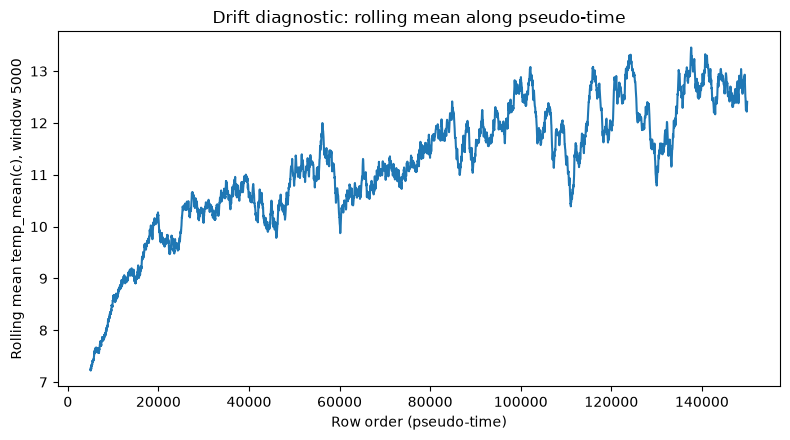

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
s=df_full[["temp_mean(c)","Pressure","global_radiation","Wind_Speed"]].iloc[:150000].copy().reset_index(drop=True)  # first 150k rows in file order, as the simulated stream (runtime-bounded; stated in notebook)
for lag in [1,2,3]: s[f"lag{lag}"]=s["temp_mean(c)"].shift(lag)
s["roll_mean5"]=s["temp_mean(c)"].shift(1).rolling(5).mean()
s=s.dropna().reset_index(drop=True)
print("Lag dataset shape:", s.shape)
# drift diagnostic: rolling mean in thirds
thirds=np.array_split(s["temp_mean(c)"].values, 3)
print("Mean temp_mean by third of pseudo-time:", [round(float(np.mean(t)),3) for t in thirds])
print("Std temp_mean by third:", [round(float(np.std(t)),3) for t in thirds])
roll=s["temp_mean(c)"].rolling(5000).mean()
plt.plot(roll.values); plt.xlabel("Row order (pseudo-time)"); plt.ylabel("Rolling mean temp_mean(c), window 5000"); plt.title("Drift diagnostic: rolling mean along pseudo-time"); plt.tight_layout(); plt.show()

## Part 4 — Static vs rolling retraining

Naive lag1 RMSE on final segment: 1.2338
Static LinearRegression RMSE final segment: 1.2247


Static RandomForest RMSE final segment: 3.2728


Rolling-retrained RandomForest RMSE (from 60% onward): 3.1258


Static RandomForest RMSE (same period): 3.167


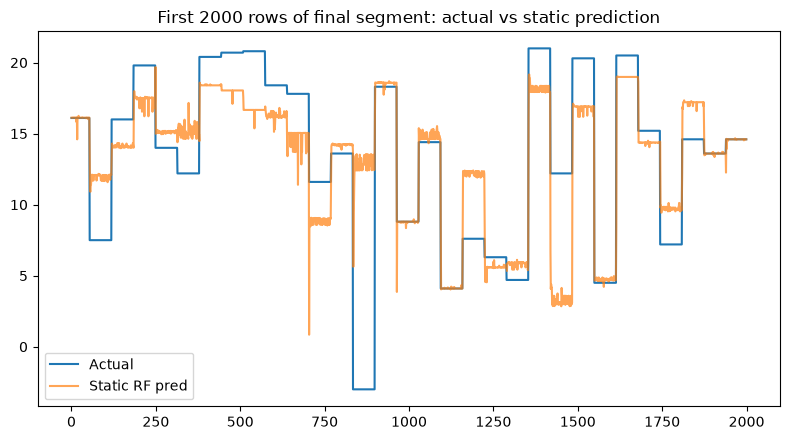

In [3]:
feats=["lag1","lag2","lag3","roll_mean5","Pressure","global_radiation","Wind_Speed"]
X=s[feats].values; y=s["temp_mean(c)"].values
n=len(s); cut1=int(n*0.6); cut2=int(n*0.8)
Xtr,ytr=X[:cut1],y[:cut1]; Xte,yte=X[cut2:],y[cut2:]
def rmse(a,b): return float(np.sqrt(mean_squared_error(a,b)))
# naive: lag1 as forecast
print("Naive lag1 RMSE on final segment:", round(rmse(yte, Xte[:,0]),4))
for name, model in [("LinearRegression",LinearRegression()),("RandomForest",RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))]:
    model.fit(Xtr,ytr); print(f"Static {name} RMSE final segment:", round(rmse(yte, model.predict(Xte)),4))
# Rolling: retrain every 10000 rows on the most recent 30000 rows, predict next block
block=10000; preds=[]; trues=[]
start=cut1
while start<n:
    end=min(start+block,n); hist_start=max(0,start-30000)
    m=RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1); m.fit(X[hist_start:start], y[hist_start:start]); preds.extend(m.predict(X[start:end])); trues.extend(y[start:end]); start=end
print("Rolling-retrained RandomForest RMSE (from 60% onward):", round(rmse(np.array(trues), np.array(preds)),4))
# Static RF RMSE on same rolling period for fair comparison
m=RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1); m.fit(Xtr,ytr); print("Static RandomForest RMSE (same period):", round(rmse(y[cut1:], m.predict(X[cut1:])),4))
plt.plot(y[cut2:cut2+2000], label="Actual"); plt.plot(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(Xtr,ytr).predict(X[cut2:cut2+2000]), label="Static RF pred", alpha=0.7); plt.legend(); plt.title("First 2000 rows of final segment: actual vs static prediction"); plt.tight_layout(); plt.show()

## Part 5 — Interpretation

In [4]:
print("INTERPRETATION: If rolling retraining beats the static model on the later segment, that is evidence the relationship drifted along row order and adaptive retraining helps. If it does not, retraining frequency or window should be revisited before claiming a drift benefit.")
print("LIMITATION: Row order is a pseudo-time proxy only. With a real timestamp, seasonal decomposition and dated drift tests would replace this rolling-mean diagnostic.")

INTERPRETATION: If rolling retraining beats the static model on the later segment, that is evidence the relationship drifted along row order and adaptive retraining helps. If it does not, retraining frequency or window should be revisited before claiming a drift benefit.
LIMITATION: Row order is a pseudo-time proxy only. With a real timestamp, seasonal decomposition and dated drift tests would replace this rolling-mean diagnostic.


## Conclusion

See the printed metrics and plots above. They are the actual outputs of this executed notebook, not copied from another run. Limitations stated at the top still apply.